# Looking at distributions

One essential element of a reanalysis is that we have gridded data. 
This means that we have data for each grid cell at every point in time. 
This is a very different situation than observational time series, which consist of a single time series from a single point that may not be complete in time.

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
from pyproj import CRS
import cartopy.crs as ccrs
import dask

We start by defining the location of the DANRA dataset and then load it with `xarray`.

`xarray` works especially well with the `zarr` format, enabling lazy loading. 
This means you can analyze massive datasets interactively without loading everything into memory at once, making your workflow both efficient and scalable.

In [2]:
ds_danra_sl = xr.open_zarr(
    "s3://dmi-danra-061/single_levels_analysis.zarr",
    consolidated=True,
    storage_options={
        "anon": True,
    },
)

ds_danra_sl.attrs['suite_name'] = "danra"
ds_danra_sl

<xarray.Dataset> Size: 16TB
Dimensions:                   (time: 97400, y: 589, x: 789)
Coordinates:
  * time                      (time) datetime64[ns] 779kB 1990-09-01 ... 2023...
  * y                         (y) float64 5kB -6.095e+05 -6.07e+05 ... 8.605e+05
  * x                         (x) float64 6kB -1.999e+06 ... -2.925e+04
    lat                       (y, x) float64 4MB dask.array<chunksize=(295, 263), meta=np.ndarray>
    lon                       (y, x) float64 4MB dask.array<chunksize=(295, 263), meta=np.ndarray>
Data variables: (12/46)
    albedo                    (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    cape_column               (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    cb_column                 (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    ct_column                 (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    danra_projection          float64 8B ...
    fog                       (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    ...                        ...
    u10m                      (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    v10m                      (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    vis0m                     (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    wdir10m                   (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    ws10m                     (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    xhail                     (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.8
    contact:      Leif Denby <lcd@dmi.dk>, Danish Meteorological Institute
    description:  All prognostic variables for 1990-09-01T00:00Z to 2024-01-0...
    license:      CC-BY-4.0: https://creativecommons.org/licenses/by/4.0/
    suite_name:   danra

The dataset already contains the 10-meter wind speed as `ws10m`. To show how new variables can be derived from the existing ones, we calculate it here from the u and v components using the formula:

$$
\mathrm{wind\_speed} = \sqrt{u^2 + v^2},
$$

where $u$ and $v$ are the zonal and meridional wind components at 10 meters, respectively.

In [3]:
ds_danra_sl['wind_speed'] = np.sqrt(
    ds_danra_sl['u10m'] ** 2 + ds_danra_sl['v10m'] ** 2)
ds_danra_sl

<xarray.Dataset> Size: 16TB
Dimensions:                   (time: 97400, y: 589, x: 789)
Coordinates:
  * time                      (time) datetime64[ns] 779kB 1990-09-01 ... 2023...
  * y                         (y) float64 5kB -6.095e+05 -6.07e+05 ... 8.605e+05
  * x                         (x) float64 6kB -1.999e+06 ... -2.925e+04
    lat                       (y, x) float64 4MB dask.array<chunksize=(295, 263), meta=np.ndarray>
    lon                       (y, x) float64 4MB dask.array<chunksize=(295, 263), meta=np.ndarray>
Data variables: (12/47)
    albedo                    (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    cape_column               (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    cb_column                 (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    ct_column                 (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    danra_projection          float64 8B ...
    fog                       (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    ...                        ...
    v10m                      (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    vis0m                     (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    wdir10m                   (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    ws10m                     (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    xhail                     (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    wind_speed                (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.8
    contact:      Leif Denby <lcd@dmi.dk>, Danish Meteorological Institute
    description:  All prognostic variables for 1990-09-01T00:00Z to 2024-01-0...
    license:      CC-BY-4.0: https://creativecommons.org/licenses/by/4.0/
    suite_name:   danra

Notice how the dataset has now been expanded to include `wind_speed`.

We now define two geo locations of interest, two wind farm sites in Denmark. We will look at the wind speed distribution at these points over the entire 30-year period.

In [4]:
pt_thor_windpark = dict(lat=56.330, lon=8.0)
pt_sprogoe_windpark = dict(lat=55.34, lon=10.96)

danra_crs = ccrs.Projection(CRS.from_wkt(ds_danra_sl.danra_projection.crs_wkt))
pc_crs = ccrs.PlateCarree()

pt_thor_windpark["x"], pt_thor_windpark["y"] = danra_crs.transform_point(
    pt_thor_windpark["lon"], pt_thor_windpark["lat"], pc_crs)
pt_sprogoe_windpark["x"], pt_sprogoe_windpark["y"] = danra_crs.transform_point(
    pt_sprogoe_windpark["lon"], pt_sprogoe_windpark["lat"], pc_crs)

da_pt_thor = ds_danra_sl["wind_speed"].sel(
    x=pt_thor_windpark["x"],
    y=pt_thor_windpark["y"],
    method="nearest"
)

da_pt_sprogoe = ds_danra_sl["wind_speed"].sel(
    x=pt_sprogoe_windpark["x"],
    y=pt_sprogoe_windpark["y"],
    method="nearest"
)

da_pt_thor, da_pt_sprogoe = dask.compute(da_pt_thor, da_pt_sprogoe)

Note the ``dask.compute`` call. It loads the full timeseries for the two grid points into memory in one go, so the statistics in the following cell run almost instantaneously. The measured speedup was 10x by adding that one line, because the alternative would read each chunk file again for every single statistics operation. ``dask.compute`` is useful for multiple datasets/dataarrays, but if there is only one object to compute, it can be computed simply with e.g. ``ds.compute()``. 

Basic statistics can now be computed for the wind speed at these points.

In [5]:
# Calculate statistics of the wind speeds
counts_thor, binEdges_thor = np.histogram(
    da_pt_thor, bins=np.arange(0, 30, .5))
counts_sprogoe, binEdges_sprogoe = np.histogram(
    da_pt_sprogoe, bins=np.arange(0, 30, .5))

median_thor = np.nanmedian(da_pt_thor)
mean_thor = np.nanmean(da_pt_thor)

median_sprogoe = np.nanmedian(da_pt_sprogoe)
mean_sprogoe = np.nanmean(da_pt_sprogoe)

Finally, the wind speed distribution for the two locations over all 30 years can be compared by plotting them on top of each other. Dashed lines indicate the mean wind speed for each location.

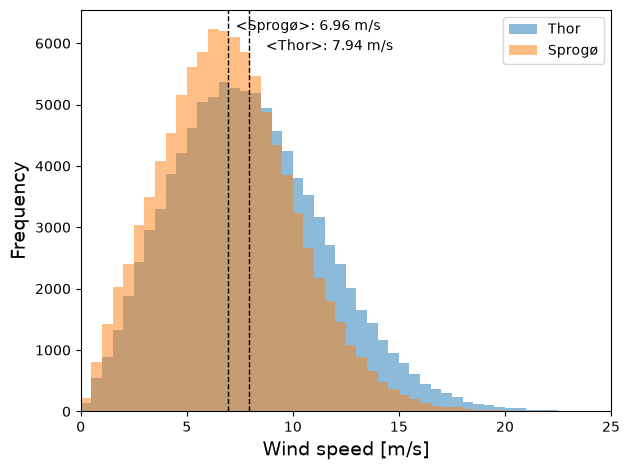

In [6]:
fig, ax = plt.subplots(1, 1, sharey=True, tight_layout=True)

ax.bar(
    binEdges_thor[:-1],
    counts_thor,
    width=np.diff(binEdges_thor),
    edgecolor=None,
    align="edge",
    alpha=0.5,
    label="Thor"
)
ax.bar(
    binEdges_sprogoe[:-1],
    counts_sprogoe,
    width=np.diff(binEdges_sprogoe),
    edgecolor=None,
    align="edge",
    alpha=0.5,
    label="Sprogø"
)
ax.legend()

ax.set_xlabel("Wind speed [m/s]", fontsize=14)
ax.set_ylabel("Frequency", fontsize=14)

ax.set_xlim(0, 25)
min_ylim, max_ylim = plt.ylim()

plt.axvline(mean_thor, color='k', linestyle='dashed', linewidth=1)
plt.axvline(mean_sprogoe, color='k', linestyle='dashed', linewidth=1)

plt.text(
    mean_thor * 1.1,
    max_ylim * 0.9,
    '<Thor>: {:.2f} m/s'.format(mean_thor)
)
plt.text(
    mean_sprogoe * 1.05, max_ylim * 0.95,
    '<Sprogø>: {:.2f} m/s'.format(mean_sprogoe)
)

plt.show()